# 음악 고객 이탈 예측 탐색적 데이터 분석

평가 항목의 데이터 특성과 주요 변수 관계 분석을 재현하는 노트북입니다.
**통합 고객표에서 학습 행만 선택해 분석하며 검증·최종 평가 자료로 관계를 탐색하지 않습니다.**
모델 학습, 피처 수정, 고객 삭제, 스케일링과 판정 기준 튜닝은 하지 않습니다.

노트북을 프로젝트 루트 또는 `notebooks` 폴더에서 열고 위에서부터 실행하세요.
추가 분석 환경은 프로젝트 루트에서 `python -m pip install -r requirements_eda.txt`로 준비합니다.
그래프와 요약은 프로젝트의 `assets/eda`, `docs/evidence`, `docs/06_탐색적데이터분석.md`에 저장합니다.

In [1]:
from pathlib import Path
import hashlib
import json
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from matplotlib import font_manager
from IPython.display import display, Image

현재위치 = Path.cwd().resolve()
후보 = [현재위치, *현재위치.parents]
프로젝트 = next((p for p in 후보 if (p / 'data/processed/customer_features_20181101_v1_with_split.csv').is_file()), None)
if 프로젝트 is None:
    raise FileNotFoundError('프로젝트 루트나 노트북 폴더에서 실행하고 고객 통합표 위치를 확인하세요.')
자료경로 = 프로젝트 / 'data/processed/customer_features_20181101_v1_with_split.csv'
그림폴더 = 프로젝트 / 'assets/eda'
근거폴더 = 프로젝트 / 'docs/evidence'
그림폴더.mkdir(parents=True, exist_ok=True)
근거폴더.mkdir(parents=True, exist_ok=True)

설치글꼴 = {f.name for f in font_manager.fontManager.ttflist}
한글글꼴 = next((f for f in ['Malgun Gothic', 'NanumGothic', 'Noto Sans CJK KR'] if f in 설치글꼴), None)
if 한글글꼴 is None:
    raise RuntimeError('한글 글꼴을 설치한 뒤 다시 실행하세요. 윈도 환경의 맑은 고딕을 권장합니다.')
plt.rcParams.update({'font.family':한글글꼴, 'axes.unicode_minus':False,
                     'font.size':11, 'axes.titlesize':14, 'axes.labelsize':11,
                     'figure.facecolor':'white', 'axes.spines.top':False, 'axes.spines.right':False})
보라,초록,회색 = '#7650A5','#27816D','#7D8794'

열이름 = {
 'active_days':'활동 일수','session_count':'세션 수','song_count':'재생 이벤트 수',
 'days_since_last_activity':'마지막 활동 경과 일수','recent_7d_song_count':'최근 7일 재생',
 'previous_7d_song_count':'이전 7일 재생','song_count_change':'주간 재생 변화',
 'thumbs_up_count':'좋아요 횟수','thumbs_down_count':'싫어요 횟수','playlist_add_count':'재생목록 추가',
 'ad_count':'광고 노출','error_count':'오류 횟수','help_count':'도움말 방문'}
수치열 = list(열이름)

def 그림저장(그림, 이름):
    경로 = 그림폴더 / 이름
    그림.tight_layout(pad=2.0)
    그림.savefig(경로, dpi=150, bbox_inches='tight', facecolor='white')
    plt.close(그림)
    display(Image(filename=str(경로)))

def 표문자(표):
    머리 = '| ' + ' | '.join(map(str, 표.columns)) + ' |'
    선 = '| ' + ' | '.join(['---'] * len(표.columns)) + ' |'
    행 = ['| ' + ' | '.join(map(str, row)) + ' |' for row in 표.itertuples(index=False, name=None)]
    return '\n'.join([머리, 선, *행])

def 집단집계(표, 열):
    결과 = 표.groupby(열, observed=True)['churn'].agg(고객수='size', 이탈수='sum')
    결과['이탈률'] = 결과['이탈수'] / 결과['고객수']
    return 결과

def 비율그림(축, 표, 제목):
    축.bar(np.arange(len(표)), 표['이탈률'] * 100, color=보라, width=.62)
    축.set_xticks(np.arange(len(표)), [f'{k}\n고객 {int(row.고객수):,}명' for k,row in 표.iterrows()])
    최대 = max(float(표['이탈률'].max() * 100), 1)
    축.set_ylim(0, 최대 * 1.4)
    for i, (_, row) in enumerate(표.iterrows()):
        축.text(i, row['이탈률'] * 100 + 최대 * .04, f"{row['이탈률']:.2%}", ha='center')
    축.axhline(학습['churn'].mean() * 100, color=회색, linestyle='--', linewidth=1, label='학습 전체 이탈률')
    축.set_ylabel('이탈 비율 (%)')
    축.set_title(제목)
    축.legend(frameon=False, fontsize=9)

## 1 분석 대상과 입력 품질

학습 자료만 추출한 뒤 자료형·결측·무한대·중복과 재생 횟수 계산식을 확인합니다.
이 검사는 이미 집계한 고객표에 대한 검사이며, 12기가급 원본 검사를 다시 실행하는 것은 아닙니다.

In [2]:
원본해시 = hashlib.sha256(자료경로.read_bytes()).hexdigest()
전체 = pd.read_csv(자료경로, dtype={'user_id':'string'}, encoding='utf-8-sig')
필요열 = ['user_id', *수치열, 'level_last', 'churn', 'split']
assert set(필요열).issubset(전체.columns)
학습 = 전체.loc[전체['split'].eq('train'), 필요열].copy()
assert len(학습) == 12697 and int(학습['churn'].sum()) == 724
assert 학습['user_id'].notna().all() and not 학습['user_id'].duplicated().any()
assert 학습[수치열].select_dtypes(include='number').shape[1] == 13
assert 학습[필요열].notna().all().all()
assert np.isfinite(학습[수치열].to_numpy(dtype=float)).all()
assert set(학습['level_last']) == {'free','paid'} and set(학습['churn']) == {0,1}
assert np.allclose(학습.song_count_change, 학습.recent_7d_song_count - 학습.previous_7d_song_count)
assert (학습.song_count >= 학습.recent_7d_song_count + 학습.previous_7d_song_count).all()

품질 = pd.DataFrame({
 '항목':[열이름.get(c, '이용 등급' if c=='level_last' else '이탈 정답') for c in [*수치열,'level_last','churn']],
 '자료형':[str(학습[c].dtype) for c in [*수치열,'level_last','churn']],
 '결측 수':[int(학습[c].isna().sum()) for c in [*수치열,'level_last','churn']]})
display(품질)
print(f'분석 고객 {len(학습):,}명 / 이탈 {int(학습.churn.sum()):,}명 / 이탈 비율 {학습.churn.mean():.2%}')
print('고객 중복·결측·무한대 없음, 재생 횟수 계산식 일치')

,항목,자료형,결측 수
0,활동 일수,int64,0
1,세션 수,int64,0
2,재생 이벤트 수,int64,0
3,마지막 활동 경과 일수,float64,0
4,최근 7일 재생,int64,0
5,이전 7일 재생,int64,0
6,주간 재생 변화,int64,0
7,좋아요 횟수,int64,0
8,싫어요 횟수,int64,0
9,재생목록 추가,int64,0


분석 고객 12,697명 / 이탈 724명 / 이탈 비율 5.70%
고객 중복·결측·무한대 없음, 재생 횟수 계산식 일치


## 2 이탈 정답 분포

클래스 불균형을 먼저 확인합니다. 이탈 비율이 낮으면 모든 고객을 유지로 예측해도 정확도가 높을 수 있습니다.

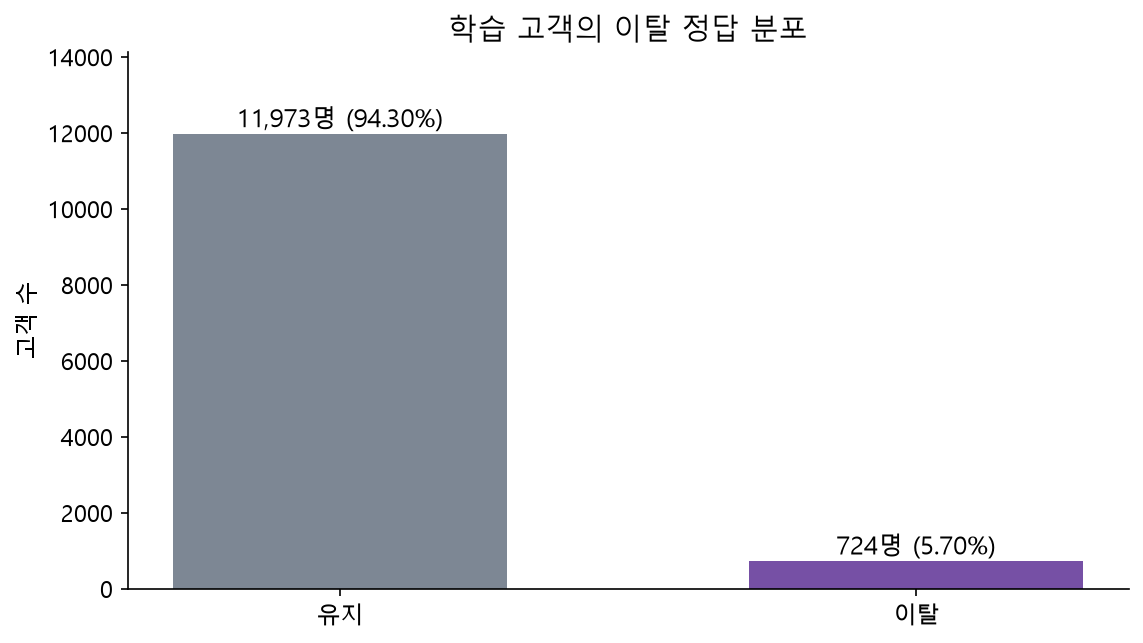

In [3]:
정답분포 = 학습['churn'].value_counts().reindex([0,1]).rename(index={0:'유지',1:'이탈'})
그림,축 = plt.subplots(figsize=(8,4.7))
축.bar(정답분포.index, 정답분포.values, color=[회색,보라], width=.58)
for i,값 in enumerate(정답분포.values):
    축.text(i, 값 + 180, f'{값:,}명 ({값 / len(학습):.2%})', ha='center', fontsize=12)
축.set_ylim(0, 정답분포.max() * 1.18)
축.set_ylabel('고객 수')
축.set_title('학습 고객의 이탈 정답 분포')
그림저장(그림,'01_이탈정답_분포.png')

## 3 수치형 피처 분포와 0의 의미

원래 값을 자르거나 삭제하지 않고 전체 범위를 표시합니다. 큰 값의 꼬리, 빈도가 높은 0, 음수 변화량을 함께 확인합니다.

,피처,최솟값,중앙값,99백분위,최댓값,0 비율(%)
0,활동 일수,1.0,6.00,24.000,28.000,0.000
1,세션 수,1.0,5.00,34.000,70.000,0.000
2,재생 이벤트 수,0.0,267.00,2827.120,5731.000,0.244
3,마지막 활동 경과 일수,0.0,2.49,26.037,27.974,0.000
4,최근 7일 재생,0.0,50.00,903.040,1584.000,27.857
5,이전 7일 재생,0.0,49.00,894.000,1803.000,27.605
6,주간 재생 변화,-1233.0,0.00,592.000,1113.000,11.081
7,좋아요 횟수,0.0,14.00,167.000,359.000,4.970
8,싫어요 횟수,0.0,3.00,33.000,70.000,19.469
9,재생목록 추가,0.0,8.00,82.040,166.000,9.278


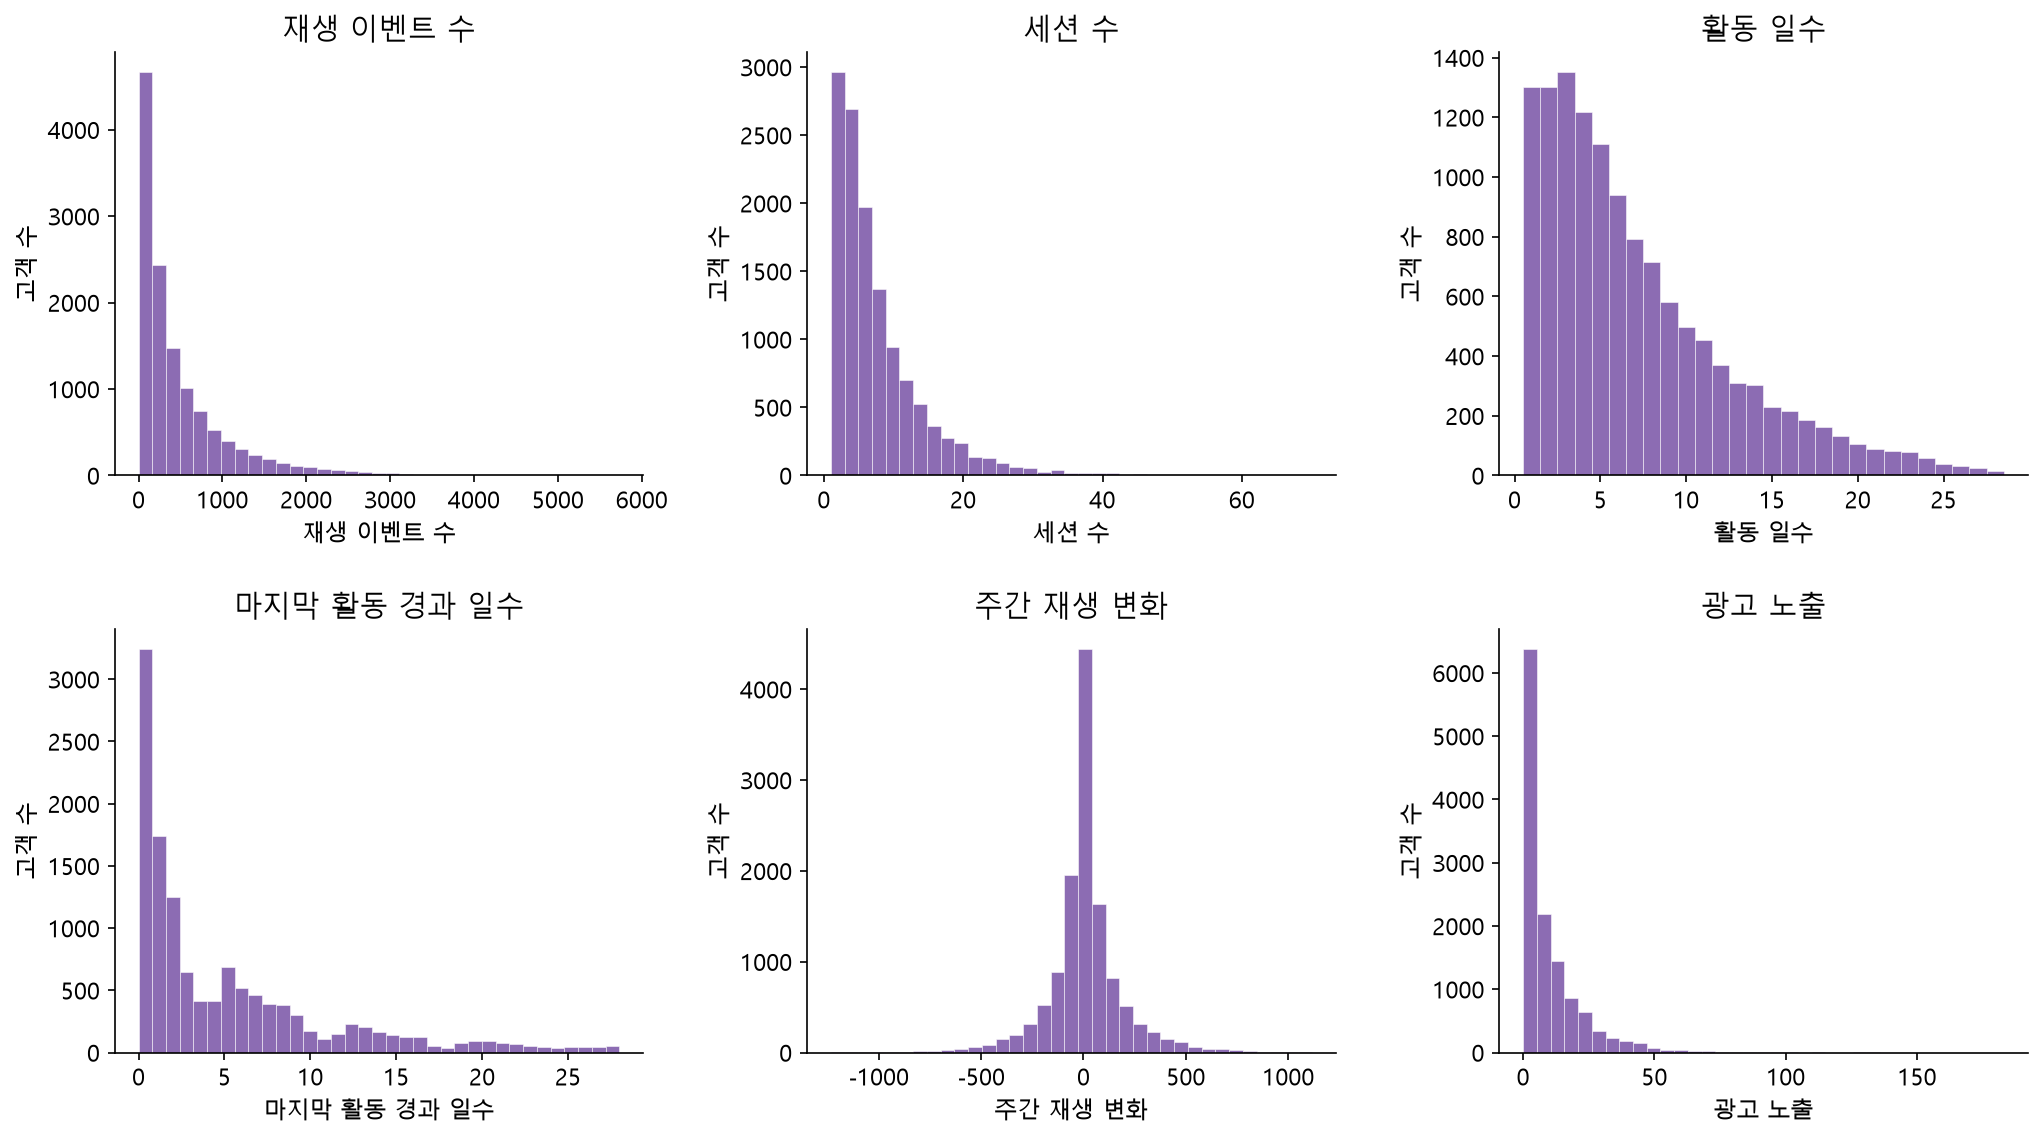

In [4]:
분포표 = pd.DataFrame([{
 '피처':열이름[c], '최솟값':학습[c].min(), '중앙값':학습[c].median(),
 '99백분위':학습[c].quantile(.99), '최댓값':학습[c].max(),
 '0 비율(%)':학습[c].eq(0).mean()*100} for c in 수치열])
display(분포표.round(3))
그림,축들 = plt.subplots(2,3,figsize=(14,8))
for 축,c in zip(축들.ravel(),['song_count','session_count','active_days','days_since_last_activity','song_count_change','ad_count']):
    구간 = np.arange(.5,29.5,1) if c=='active_days' else 35
    축.hist(학습[c], bins=구간, color=보라, alpha=.84, edgecolor='white', linewidth=.3)
    축.set_title(열이름[c]); 축.set_xlabel(열이름[c]); 축.set_ylabel('고객 수')
그림저장(그림,'02_수치형_분포.png')

## 4 이용 등급과 주간 이용 변화의 관계

그룹의 고객 수를 함께 표시해 분모를 확인합니다. 관찰된 비율의 차이로 제시하며 원인·효과 또는 다른 시점에서도 유지되는 관계라고 단정하지 않습니다.

,고객수,이탈수,이탈률
이용 등급,,,
무료,5943,242,0.040720
유료,6754,482,0.071365


,고객수,이탈수,이탈률
주간 이용 변화,,,
감소,5540,323,0.058303
변화 없음,1407,39,0.027719
증가,5750,362,0.062957


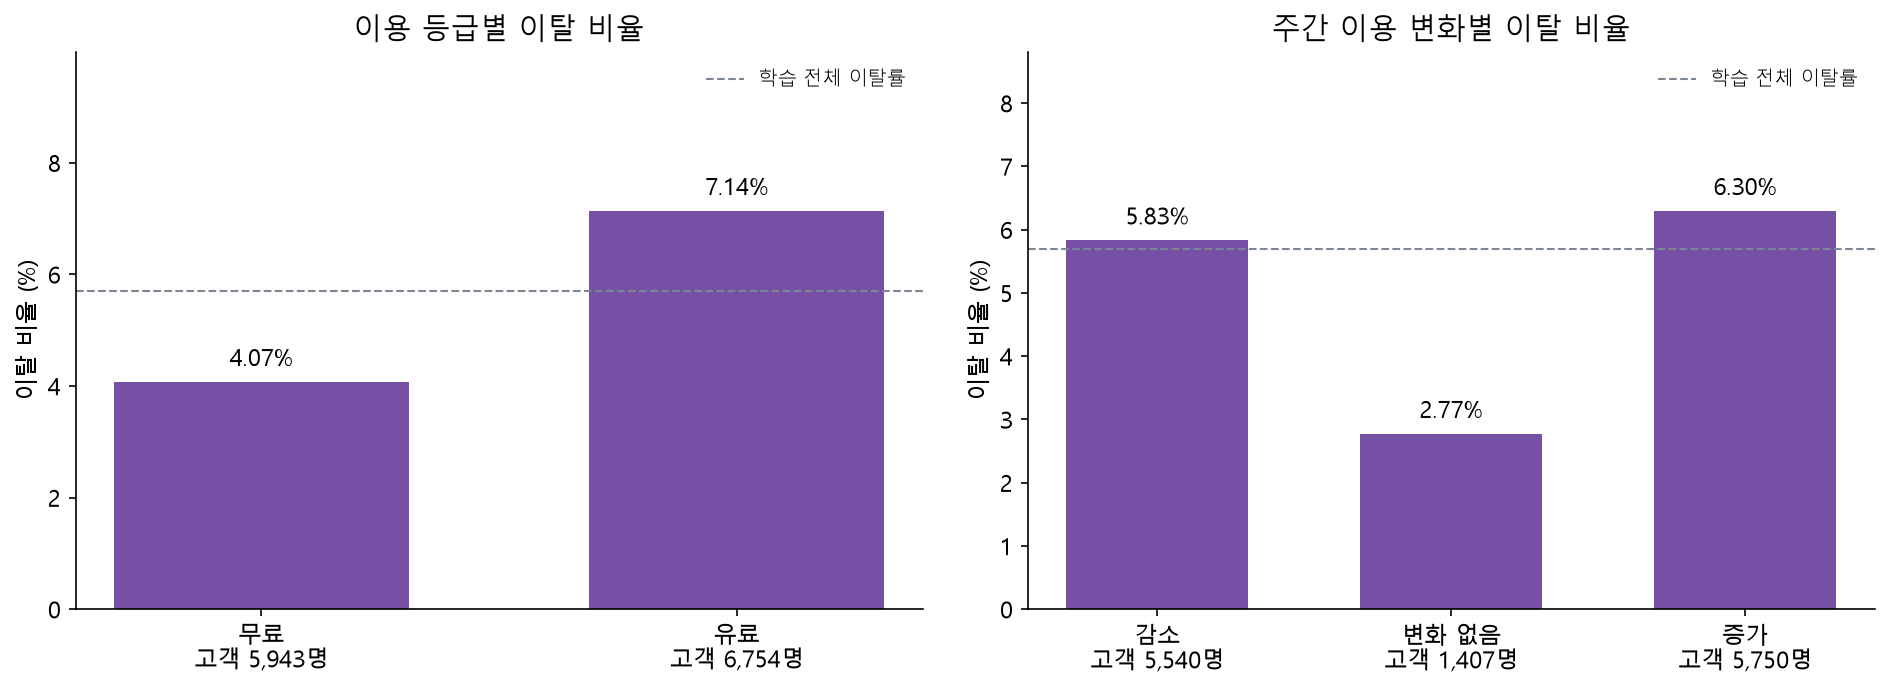

In [5]:
분석 = 학습.copy()
분석['이용 등급'] = 분석.level_last.map({'free':'무료','paid':'유료'})
분석['주간 이용 변화'] = pd.Categorical(
    np.where(분석.song_count_change<0,'감소',np.where(분석.song_count_change>0,'증가','변화 없음')),
    categories=['감소','변화 없음','증가'],ordered=True)
등급표 = 집단집계(분석,'이용 등급').reindex(['무료','유료'])
변화표 = 집단집계(분석,'주간 이용 변화')
display(등급표);display(변화표)
그림,축들 = plt.subplots(1,2,figsize=(13,5))
비율그림(축들[0],등급표,'이용 등급별 이탈 비율')
비율그림(축들[1],변화표,'주간 이용 변화별 이탈 비율')
그림저장(그림,'03_등급과변화_이탈관계.png')

## 5 마지막 이용과 재생 규모 구간별 이탈

설명하기 쉬운 고정 구간으로 비교합니다. 성능을 최대화하도록 구간을 탐색한 것이 아닙니다.
작은 구간은 비율이 흔들릴 수 있으므로 고객 수와 이탈 수를 같이 보고 운영 규칙을 확정하지 않습니다.

,고객수,이탈수,이탈률
마지막 활동 구간,,,
1일 미만,3689,323,0.087558
1~3일 미만,3064,172,0.056136
3~7일 미만,2503,118,0.047143
7~14일 미만,2134,75,0.035145
14~28일 미만,1307,36,0.027544


,고객수,이탈수,이탈률
재생 규모 구간,,,
0회,31,0,0.000000
1~99회,3167,59,0.018630
100~299회,3589,169,0.047088
300~999회,4103,277,0.067512
1000회 이상,1807,219,0.121195


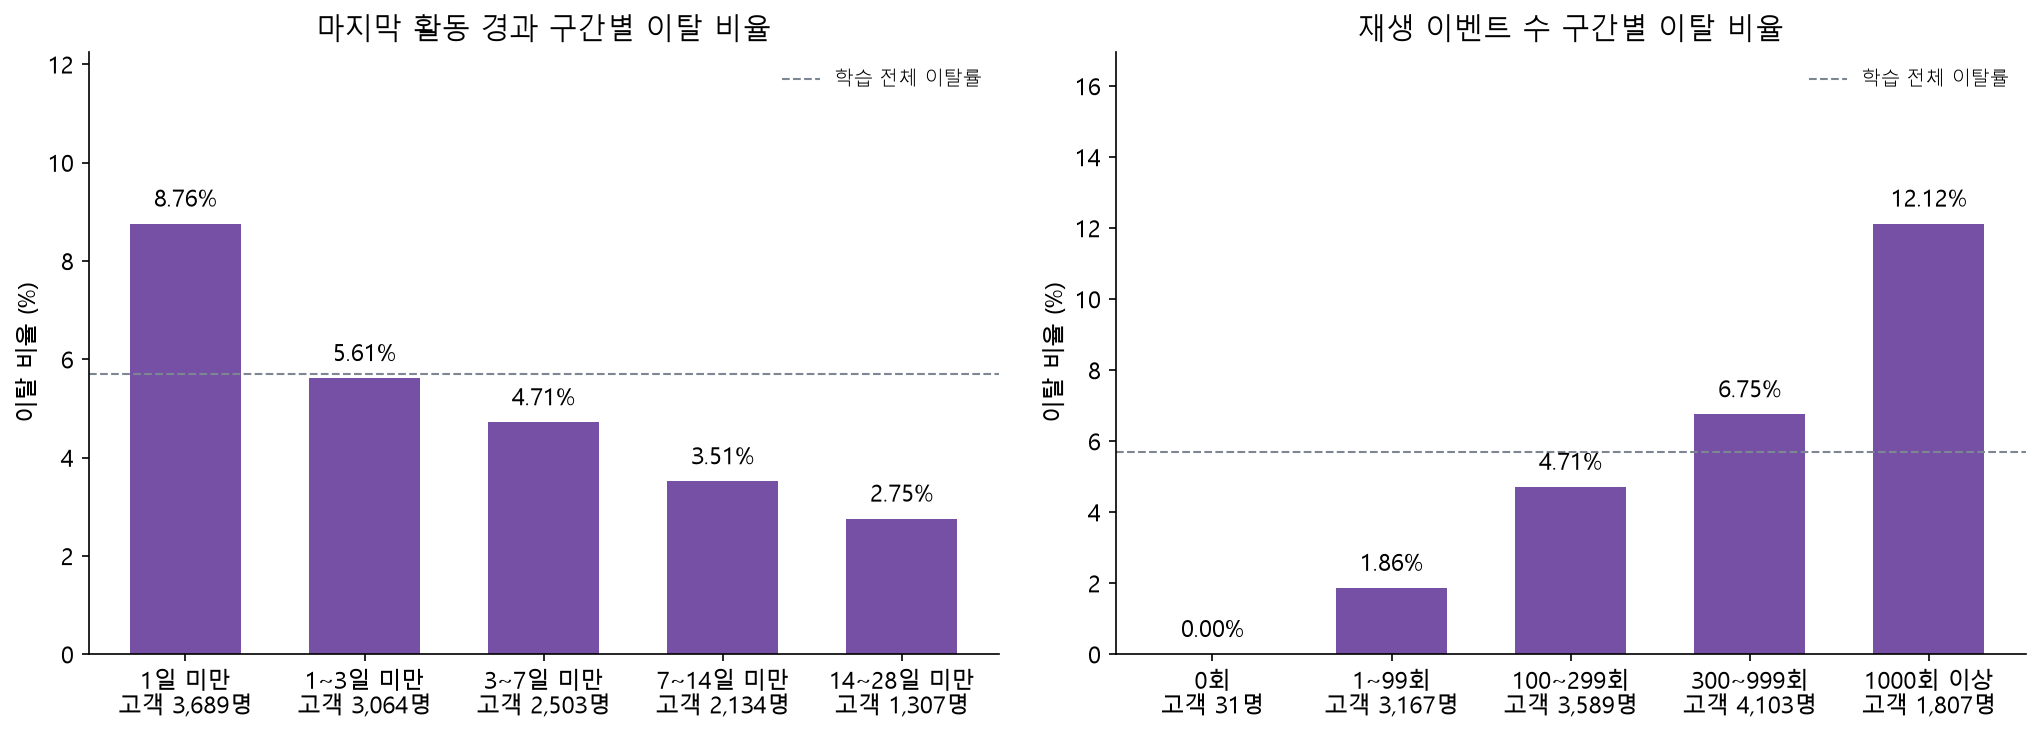

In [6]:
분석['마지막 활동 구간'] = pd.cut(분석.days_since_last_activity,
    bins=[0,1,3,7,14,28], right=False, labels=['1일 미만','1~3일 미만','3~7일 미만','7~14일 미만','14~28일 미만'])
분석['재생 규모 구간'] = pd.cut(분석.song_count,
    bins=[0,1,100,300,1000,np.inf], right=False, labels=['0회','1~99회','100~299회','300~999회','1000회 이상'])
최근표 = 집단집계(분석,'마지막 활동 구간')
규모표 = 집단집계(분석,'재생 규모 구간')
assert 최근표.고객수.sum() == len(학습) and 규모표.고객수.sum() == len(학습)
display(최근표);display(규모표)
그림,축들 = plt.subplots(1,2,figsize=(14,5.3))
비율그림(축들[0],최근표,'마지막 활동 경과 구간별 이탈 비율')
비율그림(축들[1],규모표,'재생 이벤트 수 구간별 이탈 비율')
그림저장(그림,'04_최근활동과규모_이탈관계.png')

## 6 수치 피처 사이의 관계

꼬리가 긴 분포가 있어 순위 기반 상관계수로 관련성을 살펴봅니다.
상관이 높은 이용량 피처와, 계산식으로 연결된 최근·이전 재생 수 및 변화량을 확인합니다.
상관계수만으로 피처를 삭제하지 않으며 별도의 제거 비교 실험은 아직 수행하지 않습니다.

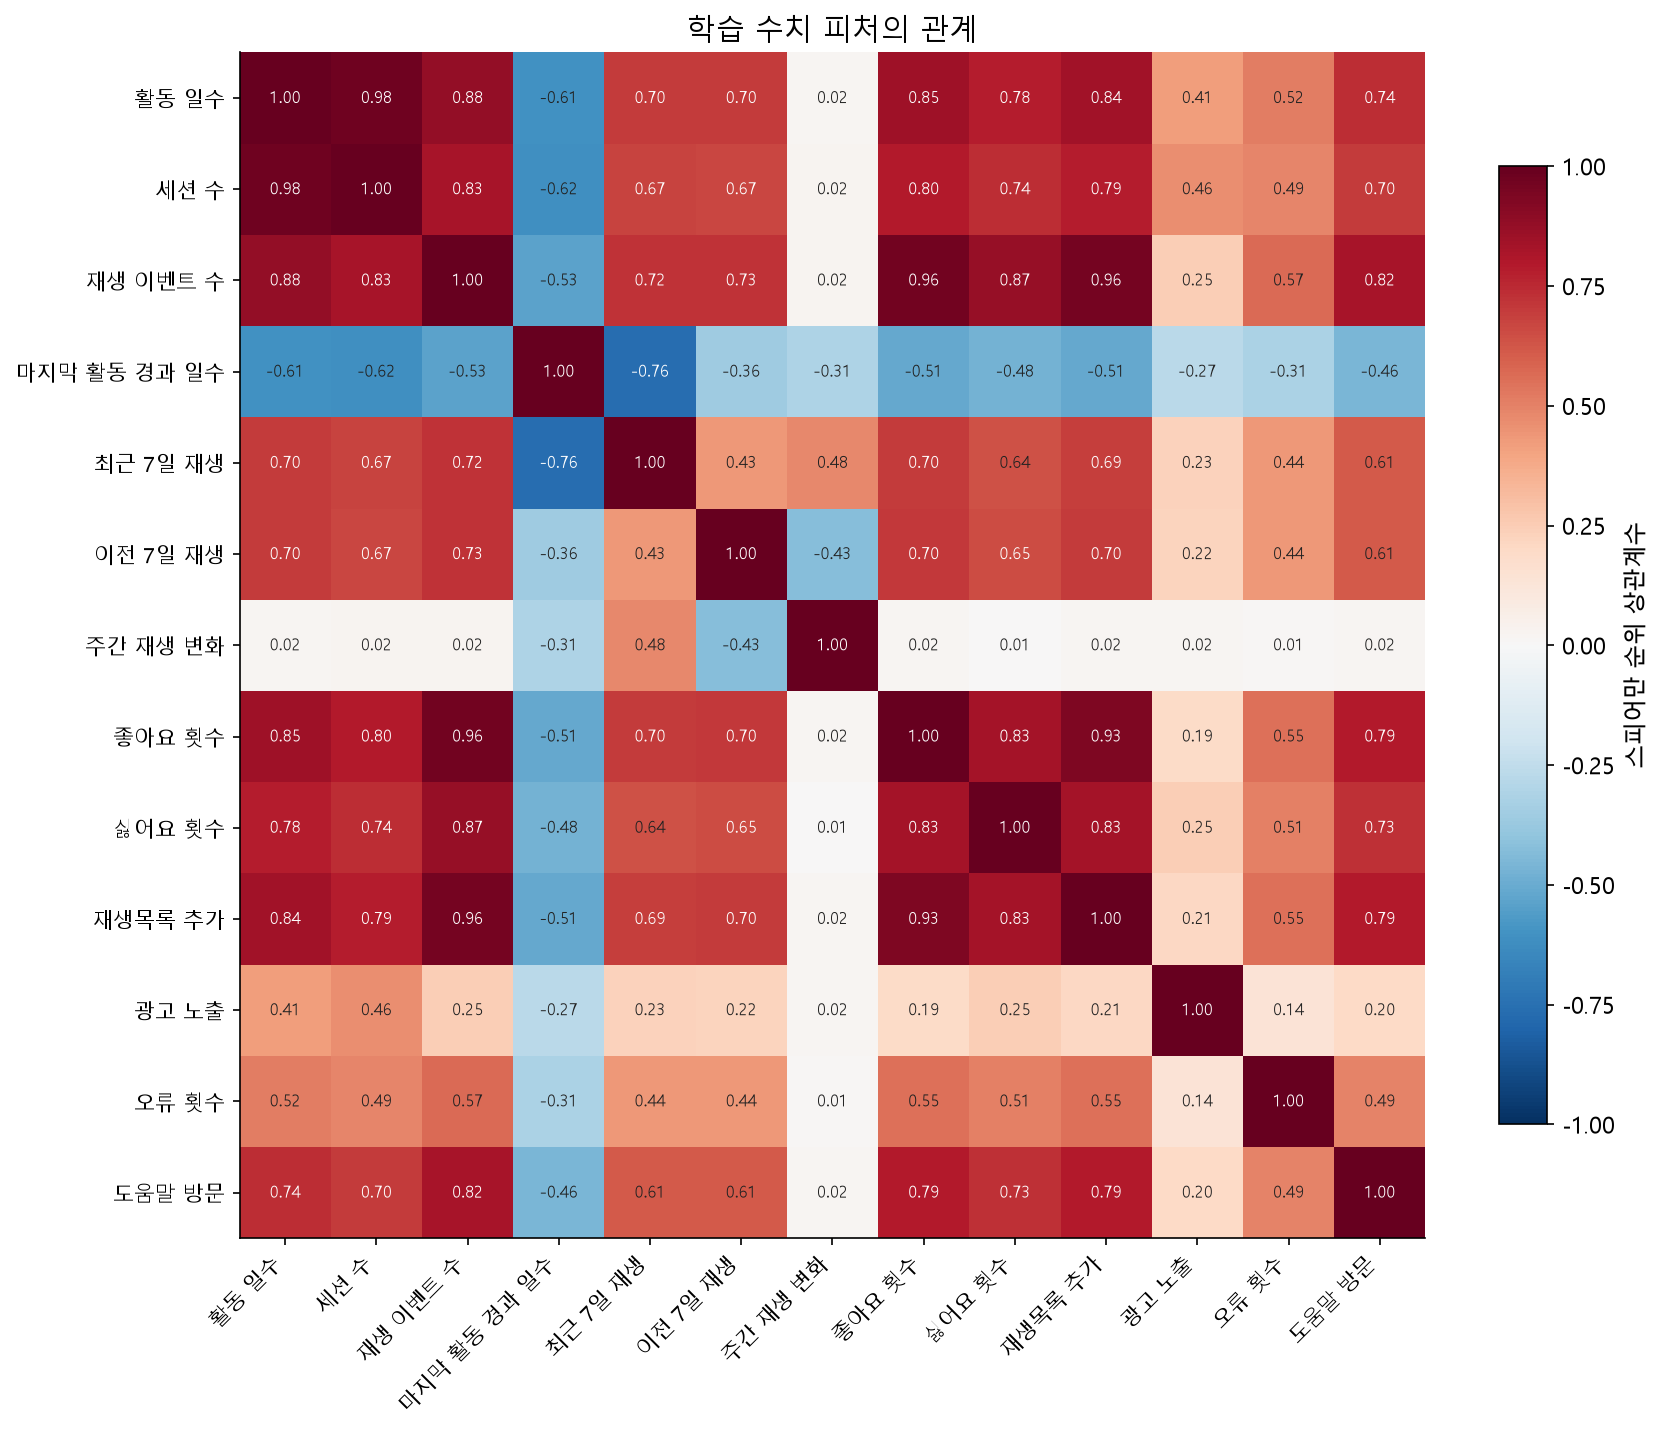

,피처 1,피처 2,상관계수
0,활동 일수,세션 수,0.975397
1,재생 이벤트 수,좋아요 횟수,0.964964
2,재생 이벤트 수,재생목록 추가,0.956001
3,좋아요 횟수,재생목록 추가,0.930714
4,활동 일수,재생 이벤트 수,0.879040
5,재생 이벤트 수,싫어요 횟수,0.869716
6,활동 일수,좋아요 횟수,0.845992
7,활동 일수,재생목록 추가,0.839773


In [7]:
상관 = 학습[수치열].corr(method='spearman').rename(index=열이름,columns=열이름)
그림,축 = plt.subplots(figsize=(12,10))
도표 = 축.imshow(상관, cmap='RdBu_r',vmin=-1,vmax=1)
축.set_xticks(range(len(상관)),상관.columns,rotation=45,ha='right',fontsize=10)
축.set_yticks(range(len(상관)),상관.index,fontsize=10)
for i in range(len(상관)):
    for j in range(len(상관)):
        값 = float(상관.iloc[i,j])
        축.text(j,i,f'{값:.2f}',ha='center',va='center',fontsize=8,color='white' if abs(값)>.65 else '#222222')
막대 = 그림.colorbar(도표,ax=축,shrink=.78)
막대.set_label('스피어만 순위 상관계수')
축.set_title('학습 수치 피처의 관계')
그림저장(그림,'05_수치형_상관관계.png')
상관쌍 = [(상관.index[i],상관.columns[j],float(상관.iloc[i,j])) for i in range(len(상관)) for j in range(i+1,len(상관))]
상관쌍 = sorted(상관쌍,key=lambda x:abs(x[2]),reverse=True)
display(pd.DataFrame(상관쌍[:8],columns=['피처 1','피처 2','상관계수']))

## 7 수치 피처와 이탈 정답의 관련성

각 피처와 이탈 정답의 단변량 순위 상관입니다. 예측 모델의 중요도나 원인 분석이 아니며 상관이 작다고 쓸모없는 피처라고 단정하지 않습니다.

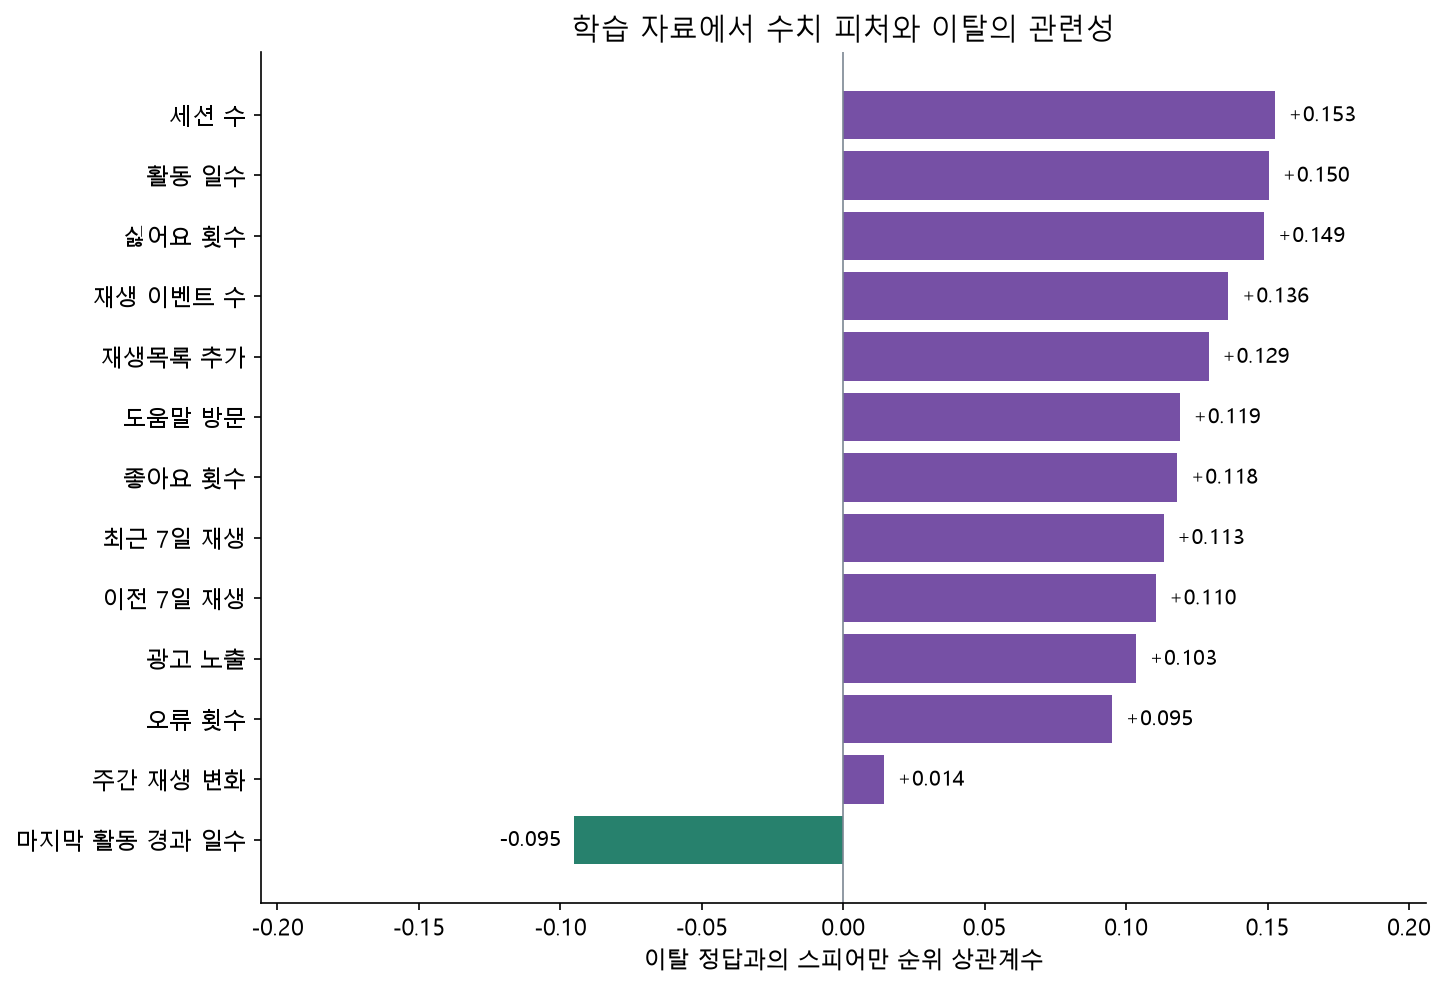

,정답과의 상관계수
세션 수,0.152569
활동 일수,0.150454
싫어요 횟수,0.148846
재생 이벤트 수,0.136137
재생목록 추가,0.129148
도움말 방문,0.118972
좋아요 횟수,0.118089
최근 7일 재생,0.113210
이전 7일 재생,0.110439
광고 노출,0.103489


In [8]:
정답상관 = 학습[[*수치열,'churn']].corr(method='spearman')['churn'].drop('churn').rename(index=열이름)
그림순서 = 정답상관.sort_values()
그림,축 = plt.subplots(figsize=(10,7))
축.barh(그림순서.index,그림순서.values,color=[보라 if v>=0 else 초록 for v in 그림순서])
축.axvline(0,color=회색,linewidth=.8)
최대 = max(float(그림순서.abs().max()),.01)
축.set_xlim(-최대*1.35,최대*1.35)
for i,값 in enumerate(그림순서):
    축.text(값 + (최대*.03 if 값>=0 else -최대*.03),i,f'{값:+.3f}',va='center',ha='left' if 값>=0 else 'right',fontsize=10)
축.set_xlabel('이탈 정답과의 스피어만 순위 상관계수')
축.set_title('학습 자료에서 수치 피처와 이탈의 관련성')
그림저장(그림,'06_피처와이탈_관련성.png')
display(정답상관.reindex(정답상관.abs().sort_values(ascending=False).index).to_frame('정답과의 상관계수'))

## 8 요약 저장과 해석

그래프마다 관찰 결과, 처리 선택과 해석의 한계를 문서로 남깁니다.
표준화나 인코딩을 이 분석에서 새로 학습하지 않으며 원본과 고객별 자료를 변경하지 않습니다.

In [9]:
def 읽기표(표):
    결과 = 표.reset_index().copy()
    결과['이탈률'] = 결과['이탈률'].map(lambda v:f'{v:.2%}')
    return 결과

요약 = {
 '분석 자료':'공통 통합표의 학습 행만 사용', '자료 sha256':원본해시,
 '학습 고객 수':len(학습), '학습 이탈 고객 수':int(학습.churn.sum()),
 '학습 이탈 비율':float(학습.churn.mean()),'학습 중복 고객':int(학습.user_id.duplicated().sum()),
 '학습 결측 수':int(학습[필요열].isna().sum().sum()),
 '재생 변화 계산식 일치':bool(np.allclose(학습.song_count_change,학습.recent_7d_song_count-학습.previous_7d_song_count)),
 '수치 분포':분포표.to_dict(orient='records'),
 '이용 등급':등급표.reset_index().to_dict(orient='records'),
 '주간 이용 변화':변화표.reset_index().to_dict(orient='records'),
 '마지막 활동 구간':최근표.reset_index().to_dict(orient='records'),
 '재생 규모 구간':규모표.reset_index().to_dict(orient='records'),
 '상관이 큰 피처 쌍':[{'피처1':a,'피처2':b,'상관계수':v} for a,b,v in 상관쌍[:8]],
 '이탈 정답과의 상관':정답상관.to_dict()}
(근거폴더/'탐색분석_수치.json').write_text(json.dumps(요약,ensure_ascii=False,indent=2),encoding='utf-8')
분포표.to_csv(근거폴더/'탐색분석_수치분포.csv',index=False,encoding='utf-8-sig')
문서 = f"""# 탐색적 데이터 분석

분석 기준은 공통 고객표의 학습 고객 {len(학습):,}명입니다. 모델이나 전처리 규칙을 새로 맞추지 않고 분포와 관계를 확인했습니다.
검증·최종 평가 자료의 관계를 추가로 탐색하지 않았으며 원본이나 고객표를 변경하지 않았습니다.

## 1 입력 품질과 분석 범위

학습 고객 중복과 결측은 각각 0건이며 수치형 무한대가 없습니다. 수치형 13개와 무료·유료 1개를 대상으로 합니다.
최근 재생 수에서 이전 재생 수를 뺀 값이 주간 변화량과 일치하고, 두 주의 재생 합은 전체 관찰 재생 수를 넘지 않습니다.
이 검사는 집계 고객표 대상이며 대용량 원본의 구조 검사는 [전처리 결과서](01_데이터전처리_결과서.md)에 기록했습니다.

## 2 정답 분포

![학습 고객의 이탈 정답 분포](../assets/eda/01_이탈정답_분포.png)

이탈은 {int(학습.churn.sum()):,}명으로 {학습.churn.mean():.2%}입니다. 전체 고객표의 5.71%와 분모가 다릅니다.
모두 유지로 예측하는 학습 정확도도 {1-학습.churn.mean():.2%}이므로 정확도만으로 학습 성능을 평가하지 않습니다.

## 3 수치형 분포와 처리 선택

![수치형 피처 분포](../assets/eda/02_수치형_분포.png)

재생 수 중앙값은 {학습.song_count.median():,.0f}회, 최댓값은 {학습.song_count.max():,}회로 오른쪽 꼬리가 깁니다.
오류 횟수 0의 비율은 {학습.error_count.eq(0).mean():.2%}, 최근 7일 재생 수 0은 {학습.recent_7d_song_count.eq(0).mean():.2%}입니다.
큰 이용량은 오류라는 근거가 없어 삭제·잘라내기를 하지 않았습니다. 0과 음수 변화량도 행동의 의미를 보존합니다.
수치형 표준화는 필요한 모델의 학습 단계에서 학습 자료 기준으로 수행합니다.

## 4 이용 등급과 주간 이용 변화

![이용 등급과 주간 변화별 이탈 비율](../assets/eda/03_등급과변화_이탈관계.png)

{표문자(읽기표(등급표))}

{표문자(읽기표(변화표))}

학습 자료에서는 유료 고객과 이용량 증가 그룹의 이탈 비율도 높았습니다. 이용 감소 하나로 고객을 선정하기 어렵다는 관찰입니다.
요금제와 이용량의 인과 효과를 증명한 결과는 아닙니다. 여러 행동 신호를 함께 모델에 반영할 근거로 사용합니다.

## 5 마지막 활동과 재생 규모

![최근 활동과 재생 규모별 이탈 비율](../assets/eda/04_최근활동과규모_이탈관계.png)

{표문자(읽기표(최근표))}

{표문자(읽기표(규모표))}

학습 자료에서는 마지막 활동 1일 미만 그룹이 {최근표.iloc[0]['이탈률']:.2%}, 14~28일 미만 그룹이 {최근표.iloc[-1]['이탈률']:.2%}였습니다.
재생 1,000회 이상 그룹은 {규모표.iloc[-1]['이탈률']:.2%}로, 최근까지 활발한 고객도 항상 유지한다고 단정하기 어렵습니다.
재생 0회 구간은 고객 {int(규모표.iloc[0]['고객수'])}명과 이탈 {int(규모표.iloc[0]['이탈수'])}명으로, 작은 표본의 0%를 안전한 집단이라는 근거로 사용하지 않습니다.
구간은 설명을 위한 고정 구간이며 성능을 최대화하도록 선택하지 않았습니다. 고객 수와 이탈 수를 함께 봅니다.
시각적으로 높은 구간이 있어도 운영 규칙이나 해지 원인으로 바로 확정하지 않습니다.

## 6 피처 사이의 관계

![수치형 피처의 순위 상관](../assets/eda/05_수치형_상관관계.png)

{표문자(pd.DataFrame(상관쌍[:5],columns=['피처 1','피처 2','순위 상관계수']).round(3))}

활동 일수와 세션 수의 순위 상관은 약 {상관.loc['활동 일수','세션 수']:.3f}, 재생 이벤트 수와 좋아요 횟수는 약 {상관.loc['재생 이벤트 수','좋아요 횟수']:.3f}입니다.
이용량 피처 사이의 높은 관련성과 함께 최근·이전 재생 및 변화량의 계산식상 종속을 확인했습니다.
관련 피처를 모두 사용할 때 로지스틱 회귀 계수를 서로 독립적인 원인으로 해석하지 않습니다. 제거 비교 실험은 월요일의 여유 작업으로 남겼습니다.

## 7 피처와 이탈 정답의 관계

![피처와 이탈 정답의 순위 상관](../assets/eda/06_피처와이탈_관련성.png)

이 그림은 학습 자료의 단변량 관련성이며 모델 중요도가 아닙니다. 다른 피처를 통제하거나 인과 효과를 추정한 분석도 아닙니다.
좋아요 횟수와 이탈의 단순 순위 상관은 약 {정답상관['좋아요 횟수']:+.3f}입니다. 개인 로지스틱 회귀에서 좋아요 계수가 음수였던 것과 단순 비교하지 않습니다.
전체 이용량과의 강한 관련성과 다른 피처의 통제 여부, 공선성 때문에 단변량 관련성과 모델 계수의 방향이 다를 수 있습니다. 어느 쪽도 인과 효과는 아닙니다.
상관이 작아도 비선형 관계나 다른 피처와의 결합 효과가 있을 수 있으므로 이 값만으로 제거하지 않습니다.

## 8 재현과 평가 항목 연결

- [실행 결과가 포함된 탐색 분석 노트북](../notebooks/05_탐색적데이터분석.ipynb)
- [수치 근거](evidence/탐색분석_수치.json)
- [분포 표](evidence/탐색분석_수치분포.csv)

분석은 정답 분포, 수치 분포, 주요 변수와 정답의 관계, 피처 간 관련성, 입력 품질을 포함합니다.
관찰 결과를 수치 보존·평가 지표·계수 해석과 연결했으며, 단순한 그래프 나열이나 모델 학습 결과와 구분했습니다.
원시 로그와 신경망 숫자 배열의 생성 규칙 검증은 이 정형 자료 탐색으로 대체하지 않습니다.
"""
if (프로젝트/'docs/doc/01_데이터전처리_결과서.md').exists():
    문서=문서.replace('(01_데이터전처리_결과서.md)','(doc/01_데이터전처리_결과서.md)')
(프로젝트/'docs/06_탐색적데이터분석.md').write_text(문서,encoding='utf-8')
assert hashlib.sha256(자료경로.read_bytes()).hexdigest()==원본해시
print('그래프 6개와 탐색 분석 문서·수치 근거 저장 완료')
print('입력 고객표가 변경되지 않았음을 확인했습니다.')

그래프 6개와 탐색 분석 문서·수치 근거 저장 완료
입력 고객표가 변경되지 않았음을 확인했습니다.
